In [1]:
import numpy as np
from matplotlib import pyplot as plt

ModuleNotFoundError: No module named 'numpy'

In [3]:
fmax    = 0.00025                       #Indicative upper limit; if make larger, better time samping
tmax    = 20000                         #Indicative upper limit; determine on basis of expected lenght of the process (note that its tail should have decayed completely)
df      = 1/tmax   
dt      = 1/(2*fmax)
N       = 1/dt/df                       #From sampling theorem
N       = round(N/2)*2

f       = np.arange(0,N*df,df)     #Note the f(N/2+1) = F_Nyquist = fmax as defined above     
w       = 2*np.pi*f
f_nq    = fmax
dw      = 2*np.pi*df
t       = np.arange(0,N*dt, dt)     #Note the t(end) is not exactly tmax as defined above


# Parameter values

alpha   = 1e-5
T1      = 0
T2      = 20
t0      = tmax/10


# Geometry

L       = 0.5
zz      = np.linspace(0,L,11)           #Observation points
Nz      = len(zz)

Gw            = np.zeros((Nz,N),dtype=complex)
G0            = np.zeros((Nz,N),dtype=complex)
Tw_trans      = np.zeros((Nz,N),dtype=complex)
T_trans       = np.zeros((Nz,N),dtype=complex)
T_steady      = np.zeros((Nz,N),dtype=complex)



In [5]:
# Define sqrt
r = (complex(1,1))/np.sqrt(2)*np.sqrt(w/alpha)  #Or: sqrt(1i*w/alpha), but then one needs to fix the sign manually

"""
for pp in range(1,N):
    if r(pp)
        
"""
"""
In this case, the steady-state and transient responses are computed 
separetely. The steady state response needs to be handled separtely
(analytically) as it does have infinite energy (i.e., division by 0 in the
domain).
"""

for kk in range(0,Nz):

    Gw[kk,:]        = ( T1*np.exp(-r*zz[kk]) - T1*np.exp(r*(zz[kk]-2*L)) - T2*np.exp(-r*(zz[kk]+L)) + T2*np.exp(r*(zz[kk]-L)) )/( 1 - np.exp(-r*2*L) );
    G0[kk,:]        = ( T1*(L-zz[kk]) + T2*zz[kk] )/L * np.ones(N);  
    Tw_trans[kk,:]  = ( Gw[kk,:] - G0[kk,:] )/(w*1j);

    # w = 0: handle separately (result obtained in Maple)
    Gw[kk,0]        = G0[kk,0];

    Tw_trans[kk,0]  = -( ((T1 + T2/2)*L - zz[kk]*(T1 - T2)/2)*(L - zz[kk])*zz[kk] )/(3*L*alpha);
    
    for jj in range(0, N):
        integrand_w     = 1/np.pi*np.real( Tw_trans[kk,:]*np.exp(1j*w*t[jj]) )*dw;
        #integrand_w = integrand_w.reshape((10, 1))
        #print(integrand_w.shape)
        T_trans[kk,jj]  = np.trapz(integrand_w, axis=0);

    T_steady[kk,:] = ( T1*(L-zz[kk]) + T2*zz[kk] )/L * np.heaviside(t, 0.5);


T_tot = T_steady + T_trans;


C:\Users\thijs\Anaconda3\lib\site-packages\ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


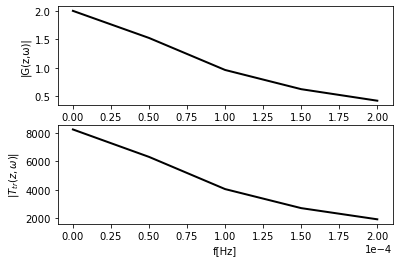

In [6]:
plt.subplot(2,1,1)
plt.plot(f[0:N//2],abs(Gw[1,0:N//2]), linewidth=2, color = 'black')
plt.ylabel('|G(z,ω)|');
plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))

plt.subplot(2,1,2)
plt.plot(f[0:N//2], abs(Tw_trans[1, 0:N//2]), linewidth=2, color = 'black');
plt.ylabel(r'$|T_{tr} (z, ω)|$')
plt.xlabel('f[Hz]')
plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))


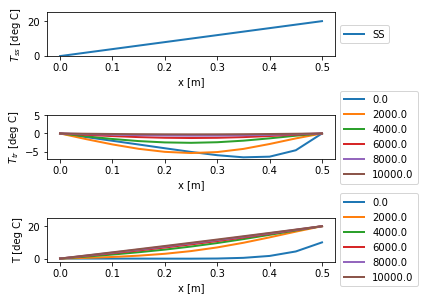

In [10]:
plt.figure();
plt.xticks( np.arange(0,zz[Nz-1],step=0.25));

plt.subplot(3,1,1)
plt.tight_layout()
plt.plot(zz, np.real(T_steady[:,2]), linewidth=2, label = 'SS');
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('x [m]')
plt.ylabel(r'$T_{ss}$ [deg C]');
plt.ylim(0, 25)


plt.subplot(3,1,2)
plt.tight_layout()
Np=5

t_index = np.arange(0, N//2+N//(2*Np), N//(2*Np))
for pp in range(len(t_index)):
    plt.plot(zz, np.real(T_trans[:,t_index[pp]]), linewidth = 2, label = t[t_index[pp]]);
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('x [m]')
plt.ylabel(r'$T_{tr}$ [deg C]')
plt.ylim(-7, 5)




plt.subplot(3,1,3)
plt.tight_layout()
Np=5;

for pp in range(len(t_index)):
    plt.plot(zz, np.real(T_tot[:,t_index[pp]]), linewidth = 2, label = t[t_index[pp]]);
plt.xlabel('x [m]')
plt.ylabel('T [deg C]')
plt.ylim(-2, 25)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
